# 04 — Attrition Modelling & Explainability
**Workforce Pulse · Phase 5**

**Prediction problem.** Binary classification: `AttritionFlag` (1 = left, 0 = stayed) from workforce attributes.
**Output.** Estimated probability of attrition *in this dataset's historical context*. It is not a forecast of
future departures.

**Pre-registered decisions (fixed before looking at results)**
| Decision | Rule | Why |
|---|---|---|
| Split | 75/25 stratified, `random_state=42`; test set untouched until final evaluation | Honest generalization estimate |
| Primary metric | **PR-AUC** (average precision); no-skill = 0.161 | Minority class focus. Accuracy is misleading (83.9 % for "nobody leaves") |
| Tuning | Grid search, 5-fold × 2 repeated stratified CV on train | Stable estimates on a small dataset |
| Model choice | XGBoost replaces LR **only if** test PR-AUC is higher **and** the paired-bootstrap 95 % CI of the difference excludes 0 | Prefer the simpler, interpretable model unless the complex one is clearly better |
| Threshold | Maximize **F2** on out-of-fold *training* predictions | Use case = supportive HR check-in: a missed leaver costs more than an unnecessary conversation |
| Probabilities | Final model wrapped in sigmoid calibration | Class weighting inflates probabilities, and dashboards show probabilities |
| Features | No IDs, no protected attributes, no undocumented rates (see `docs/feature_dictionary.md`) | Responsible-AI design |

## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
DATA = PROJECT_ROOT / "data"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

import os, json, joblib, time
os.environ["PYTHONPATH"] = str(PROJECT_ROOT)          # parallel workers must import src.*
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import mlflow, shap
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, fbeta_score
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

from src.features import PeerSalaryRatio, MODEL_NUMERIC, MODEL_CATEGORICAL
from src.evaluation import classification_metrics, threshold_table
from src.data_dictionary import PROTECTED, ID_COL

SEED = 42
df = pd.read_csv(DATA / "processed" / "hr_featured.csv")
NUMERIC = MODEL_NUMERIC + ["SalaryRatioToLevel"]             # last one created inside the pipeline
INPUT_COLS = MODEL_NUMERIC + MODEL_CATEGORICAL               # columns the pipeline receives
X, y = df[INPUT_COLS], df["AttritionFlag"]
assert not set(PROTECTED) & set(INPUT_COLS)

mlflow.set_tracking_uri(f"sqlite:///{(PROJECT_ROOT / 'mlflow.db').as_posix()}")
mlflow.set_experiment("workforce-pulse-attrition")
print(X.shape, "positives:", y.sum())

2026/11/10 16:34:56 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/10 16:34:56 INFO mlflow.store.db.utils: Updating database tables


2026/11/10 16:34:59 INFO mlflow.tracking.fluent: Experiment with name 'workforce-pulse-attrition' does not exist. Creating a new experiment.


(1470, 25) positives: 237


## 1. Stratified train / test split

In [2]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
pd.DataFrame({"rows": [len(y_tr), len(y_te)], "leavers": [y_tr.sum(), y_te.sum()],
              "rate": [y_tr.mean(), y_te.mean()]}, index=["train", "test"]).round(4)

,rows,leavers,rate
train,1102,178,0.1615
test,368,59,0.1603


## 2. Preprocessing pipeline
`PeerSalaryRatio` (JobLevel medians learned from the training fold) → scale numerics / one-hot categoricals → model.
Every transformation sits **inside** the pipeline, so cross-validation refits it on each training fold and nothing
leaks from validation or test data.

In [3]:
def make_pipeline(model, scale=True, numeric=None):
    prep = ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", numeric or NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), MODEL_CATEGORICAL),
    ], verbose_feature_names_out=False)
    return Pipeline([("peer", PeerSalaryRatio()), ("prep", prep), ("model", model)])

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
make_pipeline(LogisticRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('peer', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{

## 3. Baseline — no-skill model

In [4]:
dummy = make_pipeline(DummyClassifier(strategy="prior")).fit(X_tr, y_tr)
p_dummy = dummy.predict_proba(X_te)[:, 1]
print(f"Dummy (predicts prevalence): PR-AUC={average_precision_score(y_te, p_dummy):.3f}  "
      f"ROC-AUC={roc_auc_score(y_te, p_dummy):.3f}")
print(f"'Nobody leaves' accuracy on test: {(y_te == 0).mean():.3f}  <- with recall 0")

Dummy (predicts prevalence): PR-AUC=0.160  ROC-AUC=0.500
'Nobody leaves' accuracy on test: 0.840  <- with recall 0


## 4. Model 1 — Logistic Regression (interpretable baseline)
L2-regularized (handles the correlated tenure / pay variables). Class weighting is a tuned option, not an assumption.

In [5]:
lr_grid = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=5000)),
    {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3], "model__class_weight": [None, "balanced"]},
    scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"}, refit="pr_auc", cv=cv, n_jobs=-1)
t0 = time.time(); lr_grid.fit(X_tr, y_tr)
print(f"{time.time()-t0:.0f}s  best params:", lr_grid.best_params_)
lr_cv = pd.DataFrame(lr_grid.cv_results_)[["param_model__C", "param_model__class_weight", "mean_test_pr_auc",
                                            "std_test_pr_auc", "mean_test_roc_auc"]]
lr_cv.sort_values("mean_test_pr_auc", ascending=False).head(6).round(4)

13s  best params: {'model__C': 3, 'model__class_weight': None}


,param_model__C,param_model__class_weight,mean_test_pr_auc,std_test_pr_auc,mean_test_roc_auc
10,3.0,NaN,0.6788,0.0702,0.8471
8,1.0,NaN,0.6759,0.0704,0.8455
6,0.3,NaN,0.6691,0.0718,0.8432
4,0.1,NaN,0.6588,0.0728,0.8386
11,3.0,balanced,0.6500,0.0738,0.8354
7,0.3,balanced,0.6481,0.0742,0.8359


### 4b. Collinearity diagnostic → interpretable LR variant
*Decision added after the first SHAP review; made on training CV only, never on the test set.*

The first run's SHAP plot showed **higher MonthlyIncome increasing risk** while higher JobLevel and SalaryRatioToLevel
decreased it. That is the signature of collinearity (Phase 1: income–JobLevel ρ = 0.92, and SalaryRatioToLevel =
income / level median), not a business pattern. Coefficients split and offset each other.

Variant: drop `MonthlyIncome` from the LR's model inputs. Pay is still represented as **seniority (JobLevel) ×
relative pay (SalaryRatioToLevel)**, which is also easier to explain to HR. Rule: keep the simpler variant unless its CV
PR-AUC is lower by more than one standard error of the full model's CV estimate.

In [6]:
LR_NUMERIC_NO_INCOME = [c for c in NUMERIC if c != "MonthlyIncome"]
lr2_grid = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=5000), numeric=LR_NUMERIC_NO_INCOME),
    {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3], "model__class_weight": [None, "balanced"]},
    scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"}, refit="pr_auc", cv=cv, n_jobs=-1)
lr2_grid.fit(X_tr, y_tr)
n_splits = cv.get_n_splits()
full_mean = lr_grid.best_score_; full_se = lr_grid.cv_results_["std_test_pr_auc"][lr_grid.best_index_] / np.sqrt(n_splits)
lite_mean = lr2_grid.best_score_
USE_LITE = lite_mean >= full_mean - full_se
print(f"LR with income:    CV PR-AUC {full_mean:.4f} (SE {full_se:.4f})  params {lr_grid.best_params_}")
print(f"LR without income: CV PR-AUC {lite_mean:.4f}               params {lr2_grid.best_params_}")
print("Use interpretable variant:", USE_LITE)
if USE_LITE:
    lr_grid = lr2_grid
LR_NUMERIC = LR_NUMERIC_NO_INCOME if USE_LITE else NUMERIC

LR with income:    CV PR-AUC 0.6788 (SE 0.0222)  params {'model__C': 3, 'model__class_weight': None}
LR without income: CV PR-AUC 0.6647               params {'model__C': 0.3, 'model__class_weight': None}
Use interpretable variant: True


## 5. Model 2 — XGBoost (non-linear)
`scale_pos_weight` (≈ 5.2 = negatives / positives) is the tree-model equivalent of class weighting, tuned on/off.
Shallow trees and a small learning rate limit overfitting on 1,100 training rows.

In [7]:
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
xgb_grid = GridSearchCV(
    make_pipeline(XGBClassifier(eval_metric="logloss", tree_method="hist", subsample=0.8, colsample_bytree=0.8,
                                random_state=SEED, n_jobs=1), scale=False),
    {"model__max_depth": [2, 3, 4], "model__learning_rate": [0.03, 0.1], "model__n_estimators": [200, 400],
     "model__min_child_weight": [1, 5], "model__scale_pos_weight": [1, round(spw, 2)]},
    scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"}, refit="pr_auc", cv=cv, n_jobs=-1)
t0 = time.time(); xgb_grid.fit(X_tr, y_tr)
print(f"{time.time()-t0:.0f}s  best params:", xgb_grid.best_params_)
xgb_cv = pd.DataFrame(xgb_grid.cv_results_)
xgb_cv[["params", "mean_test_pr_auc", "std_test_pr_auc", "mean_test_roc_auc"]].sort_values(
    "mean_test_pr_auc", ascending=False).head(6).round(4)

90s  best params: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__min_child_weight': 5, 'model__n_estimators': 400, 'model__scale_pos_weight': 1}


,params,mean_test_pr_auc,std_test_pr_auc,mean_test_roc_auc
6,"{'model__learning_rate': 0.03, 'model__max_dep...",0.6339,0.0843,0.8362
28,"{'model__learning_rate': 0.1, 'model__max_dept...",0.6287,0.0796,0.8347
30,"{'model__learning_rate': 0.1, 'model__max_dept...",0.6274,0.0757,0.8356
14,"{'model__learning_rate': 0.03, 'model__max_dep...",0.6245,0.0732,0.8339
2,"{'model__learning_rate': 0.03, 'model__max_dep...",0.6244,0.0784,0.8313
3,"{'model__learning_rate': 0.03, 'model__max_dep...",0.6144,0.0738,0.8245


## 6. Objective comparison on the untouched test set

In [8]:
models = {"LogisticRegression": lr_grid.best_estimator_, "XGBoost": xgb_grid.best_estimator_}
p_test = {k: m.predict_proba(X_te)[:, 1] for k, m in models.items()}
rows = []
for name, grid in [("LogisticRegression", lr_grid), ("XGBoost", xgb_grid)]:
    i = grid.best_index_
    m = classification_metrics(y_te, p_test[name], 0.5)
    rows.append({"model": name, "cv_pr_auc": grid.cv_results_["mean_test_pr_auc"][i],
                 "cv_pr_auc_sd": grid.cv_results_["std_test_pr_auc"][i],
                 "cv_roc_auc": grid.cv_results_["mean_test_roc_auc"][i],
                 "test_pr_auc": m["pr_auc"], "test_roc_auc": m["roc_auc"], "test_brier": m["brier"]})
rows.append({"model": "Dummy (prevalence)", "test_pr_auc": average_precision_score(y_te, p_dummy),
             "test_roc_auc": 0.5, "test_brier": classification_metrics(y_te, p_dummy)["brier"]})
comparison = pd.DataFrame(rows).set_index("model")
comparison.round(4)

,cv_pr_auc,cv_pr_auc_sd,cv_roc_auc,test_pr_auc,test_roc_auc,test_brier
model,,,,,,
LogisticRegression,0.6647,0.0721,0.8427,0.5813,0.8045,0.0998
XGBoost,0.6339,0.0843,0.8362,0.5494,0.8090,0.1017
Dummy (prevalence),NaN,NaN,NaN,0.1603,0.5000,0.1346


In [9]:
# Paired bootstrap of the test PR-AUC difference (XGBoost - LR)
rng = np.random.default_rng(SEED)
yt, pl, px = y_te.to_numpy(), p_test["LogisticRegression"], p_test["XGBoost"]
diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].sum() == 0: continue
    diffs.append(average_precision_score(yt[idx], px[idx]) - average_precision_score(yt[idx], pl[idx]))
diffs = np.array(diffs)
ci = np.percentile(diffs, [2.5, 97.5])
obs = average_precision_score(yt, px) - average_precision_score(yt, pl)
xgb_wins = obs > 0 and ci[0] > 0
SELECTED = "XGBoost" if xgb_wins else "LogisticRegression"
print(f"PR-AUC difference XGB - LR = {obs:+.4f}, 95% bootstrap CI [{ci[0]:+.4f}, {ci[1]:+.4f}]")
print(f"P(XGB better) in bootstrap = {(diffs > 0).mean():.2f}")
print("Selected model by pre-registered rule:", SELECTED)

PR-AUC difference XGB - LR = -0.0319, 95% bootstrap CI [-0.1030, +0.0425]
P(XGB better) in bootstrap = 0.21
Selected model by pre-registered rule: LogisticRegression


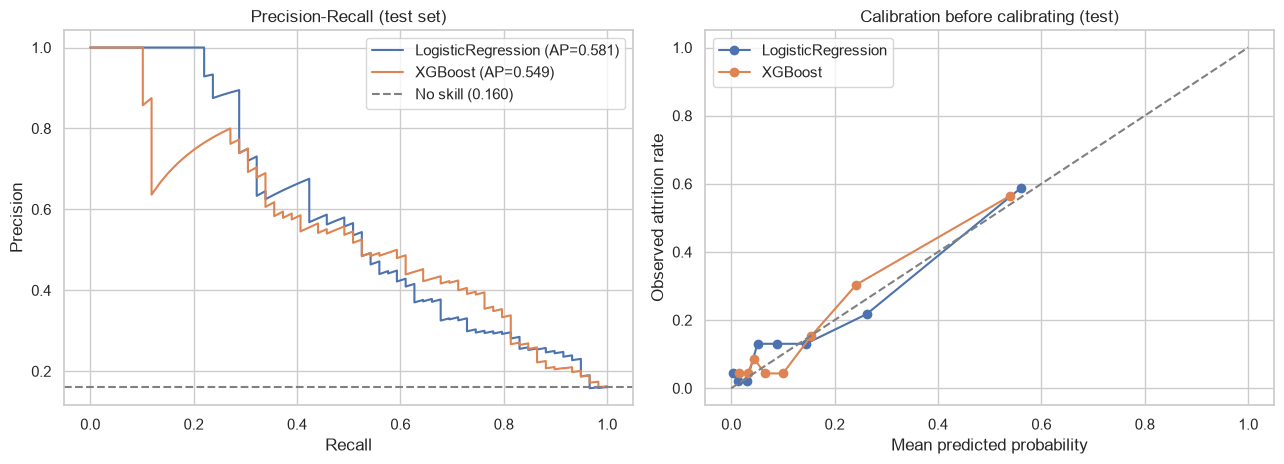

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name, p in p_test.items():
    pr, rc, _ = precision_recall_curve(y_te, p)
    axes[0].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_te, p):.3f})")
    frac, mean_pred = calibration_curve(y_te, p, n_bins=8, strategy="quantile")
    axes[1].plot(mean_pred, frac, marker="o", label=name)
axes[0].axhline(y_te.mean(), ls="--", color="grey", label=f"No skill ({y_te.mean():.3f})")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall (test set)"); axes[0].legend()
axes[1].plot([0, 1], [0, 1], ls="--", color="grey")
axes[1].set(xlabel="Mean predicted probability", ylabel="Observed attrition rate", title="Calibration before calibrating (test)")
axes[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "12_model_comparison.png", dpi=150); plt.show()

## 7. Probability calibration of the selected model
Sigmoid (Platt) calibration fitted with internal 5-fold CV on the training data only.
Ranking (PR-AUC / ROC-AUC) should barely change. Brier score and the calibration curve show whether probabilities became honest.

In [11]:
best_pipe = models[SELECTED]
cal_model = CalibratedClassifierCV(best_pipe, method="sigmoid", cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
cal_model.fit(X_tr, y_tr)
p_cal = cal_model.predict_proba(X_te)[:, 1]
pd.DataFrame({
    "uncalibrated": {"pr_auc": average_precision_score(y_te, p_test[SELECTED]), "roc_auc": roc_auc_score(y_te, p_test[SELECTED]),
                     "brier": classification_metrics(y_te, p_test[SELECTED])["brier"], "mean_pred": p_test[SELECTED].mean()},
    "calibrated": {"pr_auc": average_precision_score(y_te, p_cal), "roc_auc": roc_auc_score(y_te, p_cal),
                   "brier": classification_metrics(y_te, p_cal)["brier"], "mean_pred": p_cal.mean()},
    "actual": {"mean_pred": y_te.mean()}}).round(4)

,uncalibrated,calibrated,actual
pr_auc,0.5813,0.5825,NaN
roc_auc,0.8045,0.8042,NaN
brier,0.0998,0.0998,NaN
mean_pred,0.1440,0.1455,0.1603


## 8. Threshold selection (training data only)
Out-of-fold calibrated predictions on the **training** set → choose the threshold that maximizes F2 → apply it,
unchanged, to the test set.

In [12]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
p_oof_tr = cross_val_predict(CalibratedClassifierCV(best_pipe, method="sigmoid", cv=5), X_tr, y_tr,
                             cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
grid_t = np.round(np.arange(0.05, 0.81, 0.01), 2)
f2 = [fbeta_score(y_tr, (p_oof_tr >= t).astype(int), beta=2) for t in grid_t]
THRESHOLD = float(grid_t[int(np.argmax(f2))])
print(f"F2-optimal threshold on training OOF predictions: {THRESHOLD}")
tt = threshold_table(y_te, p_cal, np.round(np.arange(0.10, 0.61, 0.05), 2))
tt.round(3)

F2-optimal threshold on training OOF predictions: 0.14


,threshold,precision,recall,f1,flag_rate,tp,fp,fn,tn
0,0.10,0.299,0.780,0.432,0.418,46,108,13,201
1,0.15,0.367,0.678,0.476,0.296,40,69,19,240
2,0.20,0.414,0.610,0.493,0.236,36,51,23,258
3,0.25,0.459,0.576,0.511,0.201,34,40,25,269
4,0.30,0.525,0.525,0.525,0.160,31,28,28,281
5,0.35,0.574,0.458,0.509,0.128,27,20,32,289
6,0.40,0.658,0.424,0.515,0.103,25,13,34,296
7,0.45,0.645,0.339,0.444,0.084,20,11,39,298
8,0.50,0.750,0.305,0.434,0.065,18,6,41,303
9,0.55,0.895,0.288,0.436,0.052,17,2,42,307


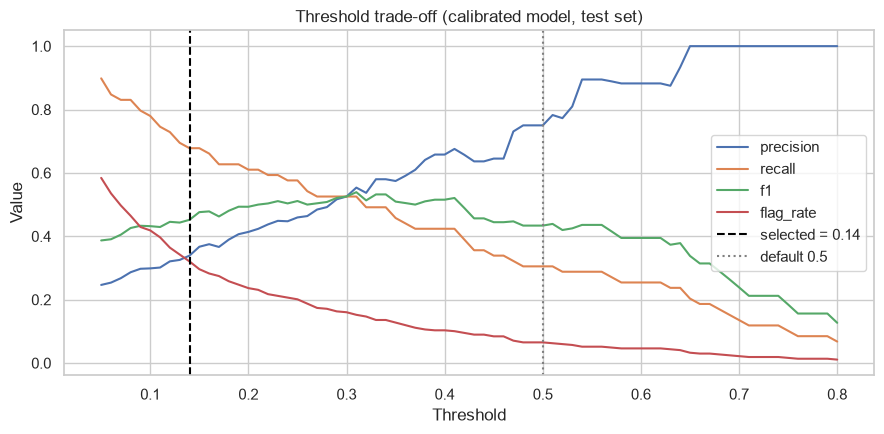

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
tt_fine = threshold_table(y_te, p_cal, np.round(np.arange(0.05, 0.81, 0.01), 2))
for c in ["precision", "recall", "f1", "flag_rate"]:
    ax.plot(tt_fine.threshold, tt_fine[c], label=c)
ax.axvline(THRESHOLD, color="black", ls="--", label=f"selected = {THRESHOLD}")
ax.axvline(0.5, color="grey", ls=":", label="default 0.5")
ax.set(xlabel="Threshold", ylabel="Value", title="Threshold trade-off (calibrated model, test set)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "13_threshold_tradeoff.png", dpi=150); plt.show()

## 9. Final test-set evaluation at the selected threshold

In [14]:
final_test = classification_metrics(y_te, p_cal, THRESHOLD)
default_test = classification_metrics(y_te, p_cal, 0.5)
pd.DataFrame({f"selected ({THRESHOLD})": final_test, "default (0.5)": default_test}).round(4)

,selected (0.14),default (0.5)
threshold,0.1400,0.5000
accuracy,0.7364,0.8723
precision,0.3390,0.7500
recall,0.6780,0.3051
f1,0.4520,0.4337
roc_auc,0.8042,0.8042
pr_auc,0.5825,0.5825
brier,0.0998,0.0998
flag_rate,0.3207,0.0652
tp,40.0000,18.0000


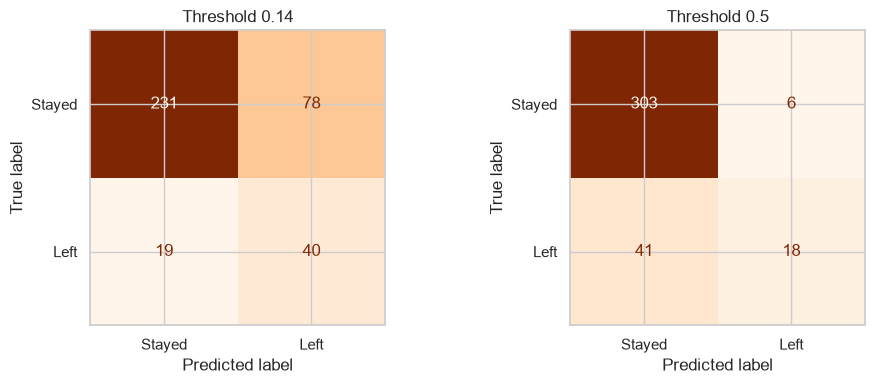

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, t in zip(axes, [THRESHOLD, 0.5]):
    ConfusionMatrixDisplay.from_predictions(y_te, (p_cal >= t).astype(int), display_labels=["Stayed", "Left"],
                                            cmap="Oranges", ax=ax, colorbar=False)
    ax.set_title(f"Threshold {t}")
plt.tight_layout(); plt.savefig(FIG_DIR / "14_confusion_matrices.png", dpi=150); plt.show()

## 10. Experiment tracking (MLflow)
One run per candidate model plus the final calibrated model. View with:
`mlflow ui --backend-store-uri sqlite:///mlflow.db`

In [16]:
for name, grid in [("LogisticRegression", lr_grid), ("XGBoost", xgb_grid)]:
    with mlflow.start_run(run_name=f"{name}-gridsearch"):
        mlflow.log_params({k.replace("model__", ""): v for k, v in grid.best_params_.items()})
        mlflow.log_params({"cv": "RepeatedStratifiedKFold(5x2)", "test_size": 0.25, "seed": SEED,
                           "n_features_in": len(INPUT_COLS)})
        mlflow.log_metrics({f"cv_{k}": v for k, v in comparison.loc[name, ["cv_pr_auc", "cv_pr_auc_sd", "cv_roc_auc"]].items()})
        mlflow.log_metrics({k: v for k, v in comparison.loc[name, ["test_pr_auc", "test_roc_auc", "test_brier"]].items()})
with mlflow.start_run(run_name=f"FINAL-{SELECTED}-calibrated"):
    mlflow.log_params({"model": SELECTED, "calibration": "sigmoid", "threshold": THRESHOLD,
                       "threshold_rule": "max F2 on train OOF", "selection_rule": "XGB only if bootstrap CI > 0",
                       "lr_monthly_income_dropped": USE_LITE})
    mlflow.log_metrics({f"test_{k}": float(v) for k, v in final_test.items() if k != "threshold"})
    mlflow.log_metric("bootstrap_prauc_diff_xgb_minus_lr", float(obs))
    mlflow.log_artifact(str(FIG_DIR / "12_model_comparison.png"))
    mlflow.log_artifact(str(FIG_DIR / "13_threshold_tradeoff.png"))
print(mlflow.search_runs()[["tags.mlflow.runName", "metrics.test_pr_auc", "metrics.test_roc_auc"]].head())

                   tags.mlflow.runName  metrics.test_pr_auc  metrics.test_roc_auc
0  FINAL-LogisticRegression-calibrated             0.582529              0.804180
1                   XGBoost-gridsearch             0.549410              0.809007
2        LogisticRegression-gridsearch             0.581308              0.804454


## 11. SHAP explainability
SHAP values explain the **selected model's** raw output (log-odds), computed on the transformed test features.
Sigmoid calibration is monotonic, so the direction and ranking of contributions are unchanged.

> SHAP shows how the model *uses* a feature, not what would happen if we changed it. A large SHAP value for
> OverTime does **not** prove that removing overtime would retain an employee.

In [17]:
prep = best_pipe[:-1]
est = best_pipe[-1]
feat_names = list(prep.named_steps["prep"].get_feature_names_out())
Xt_tr = pd.DataFrame(prep.transform(X_tr), columns=feat_names)
Xt_te = pd.DataFrame(prep.transform(X_te), columns=feat_names)
if SELECTED == "XGBoost":
    explainer = shap.TreeExplainer(est)
else:
    explainer = shap.LinearExplainer(est, Xt_tr)
sv = explainer(Xt_te)
# display unscaled values for readability in plots
Xt_te_raw = best_pipe.named_steps["peer"].transform(X_te).reset_index(drop=True)
importance = pd.Series(np.abs(sv.values).mean(0), index=feat_names).sort_values(ascending=False)
importance.head(15).round(4)

Background dataset has 1102 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1102 when initializing the masker.


OverTime_Yes                        0.6158
TotalWorkingYears                   0.5937
StockOptionLevel                    0.4205
EnvironmentSatisfaction             0.4146
YearsSinceLastPromotion             0.3560
JobInvolvement                      0.3326
NumCompaniesWorked                  0.3240
JobSatisfaction                     0.3209
YearsWithCurrManager                0.2827
DistanceFromHome                    0.2698
RelationshipSatisfaction            0.2616
RoleShareOfTenure                   0.2563
BusinessTravel_Travel_Frequently    0.2548
JobRole_Laboratory Technician       0.2282
SalaryRatioToLevel                  0.1873
dtype: float64

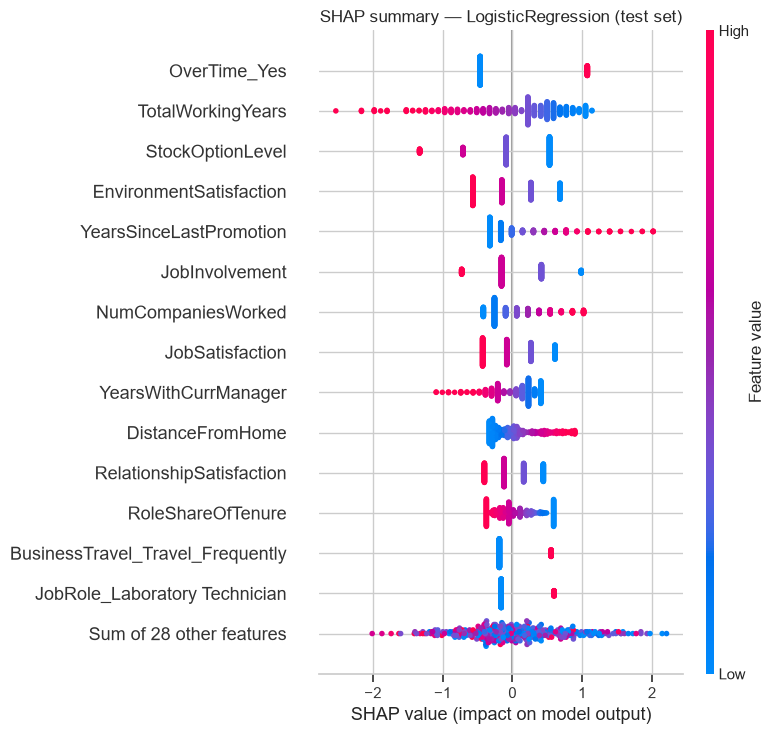

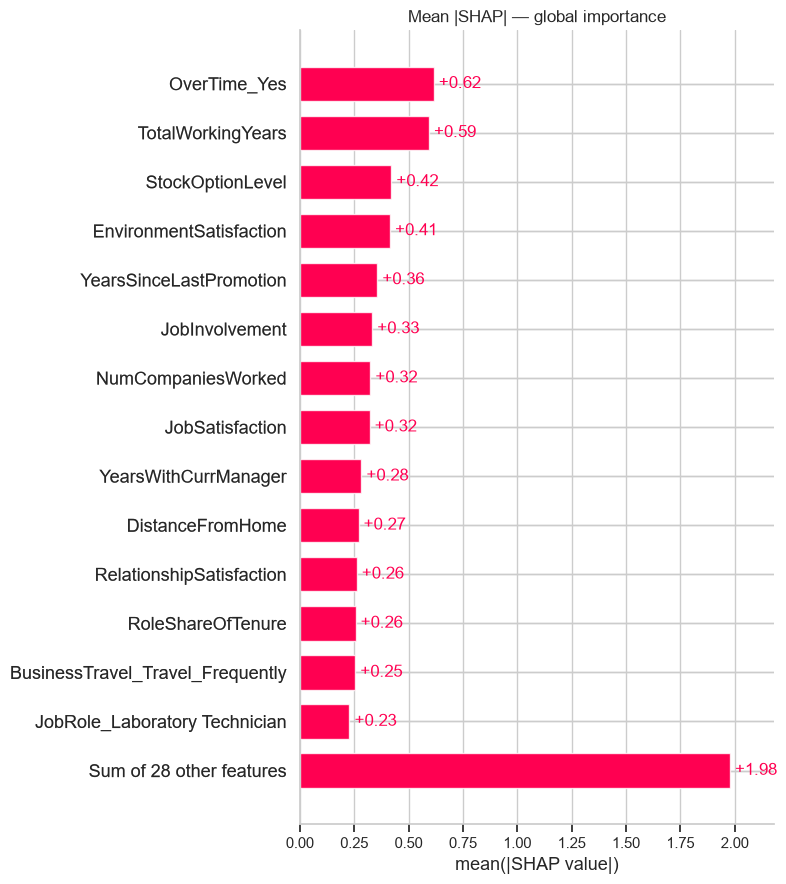

In [18]:
plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title(f"SHAP summary — {SELECTED} (test set)"); plt.tight_layout()
plt.savefig(FIG_DIR / "15_shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()
plt.figure()
shap.plots.bar(sv, max_display=15, show=False)
plt.title("Mean |SHAP| — global importance"); plt.tight_layout()
plt.savefig(FIG_DIR / "16_shap_importance.png", dpi=150, bbox_inches="tight"); plt.show()

In [19]:
# Agreement check: does the other model rank features similarly?
other = "XGBoost" if SELECTED == "LogisticRegression" else "LogisticRegression"
op = models[other]
o_names = list(op[:-1].named_steps["prep"].get_feature_names_out())
o_X_tr = pd.DataFrame(op[:-1].transform(X_tr), columns=o_names)
o_X_te = pd.DataFrame(op[:-1].transform(X_te), columns=o_names)
o_exp = shap.TreeExplainer(op[-1]) if other == "XGBoost" else shap.LinearExplainer(op[-1], o_X_tr)
o_imp = pd.Series(np.abs(o_exp(o_X_te).values).mean(0), index=o_names)
agree = pd.DataFrame({SELECTED: importance.rank(ascending=False), other: o_imp.rank(ascending=False)}).sort_values(SELECTED)
print("Spearman rank agreement of global importance:", round(agree.corr(method="spearman").iloc[0, 1], 3))
agree.head(10)

Spearman rank agreement of global importance: 0.877


,LogisticRegression,XGBoost
OverTime_Yes,1.0,1.0
TotalWorkingYears,2.0,9.0
StockOptionLevel,3.0,2.0
EnvironmentSatisfaction,4.0,3.0
YearsSinceLastPromotion,5.0,16.0
JobInvolvement,6.0,13.0
NumCompaniesWorked,7.0,4.0
JobSatisfaction,8.0,12.0
YearsWithCurrManager,9.0,7.0
DistanceFromHome,10.0,6.0


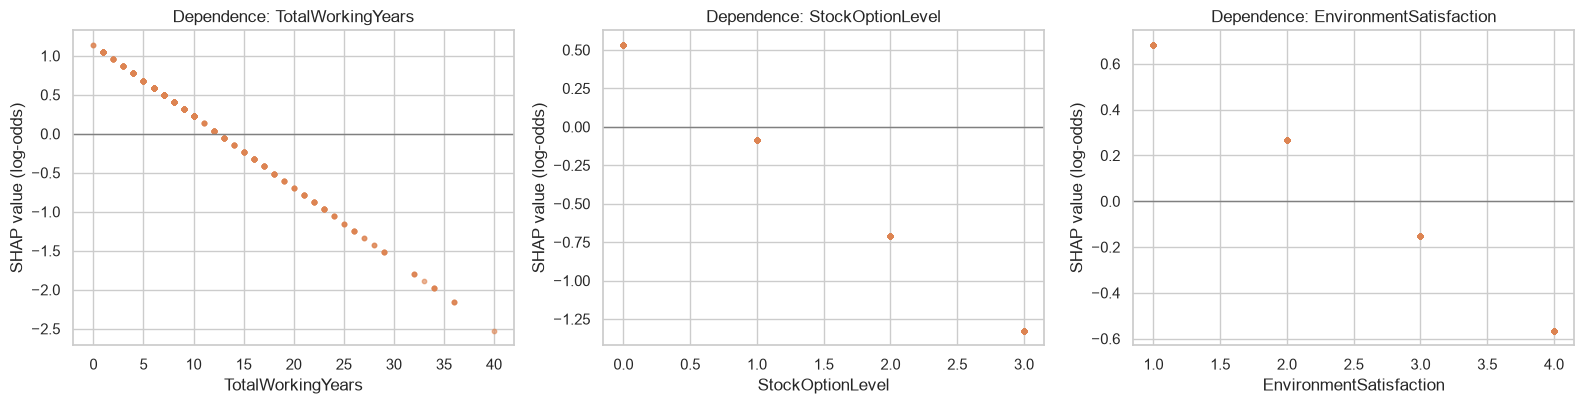

In [20]:
top3 = [f for f in importance.index if f in NUMERIC][:3]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, f in zip(axes, top3):
    col = feat_names.index(f)
    ax.scatter(Xt_te_raw[f], sv.values[:, col], s=10, alpha=.6, color="#DD8452")
    ax.axhline(0, color="grey", lw=1); ax.set(xlabel=f, ylabel="SHAP value (log-odds)", title=f"Dependence: {f}")
plt.tight_layout(); plt.savefig(FIG_DIR / "17_shap_dependence.png", dpi=150); plt.show()

highest: EmployeeNumber=1273, calibrated p=0.963, actual=1


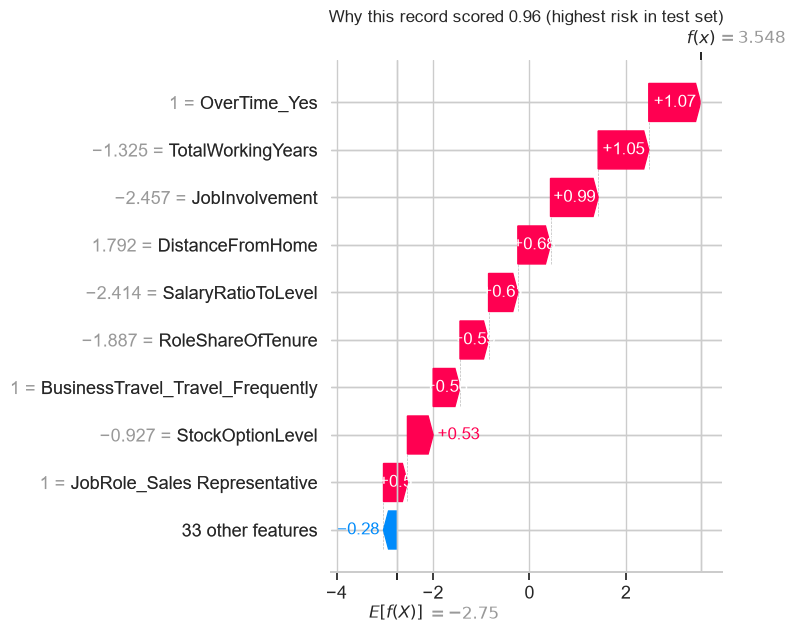

median: EmployeeNumber=24, calibrated p=0.069, actual=0


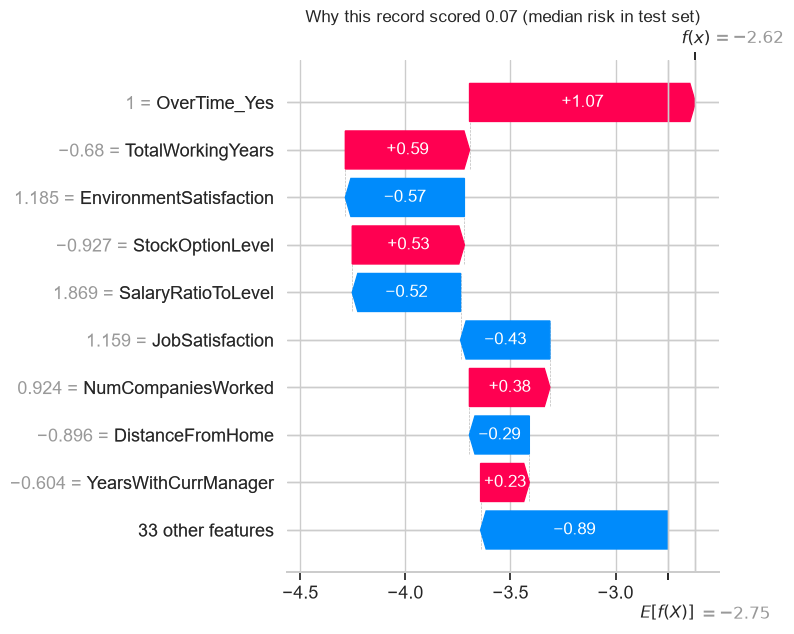

In [21]:
# Individual explanations: highest-scored test record and a typical (median-score) record
order = np.argsort(p_cal)
for label, i in [("highest", order[-1]), ("median", order[len(order) // 2])]:
    print(f"{label}: EmployeeNumber={df.loc[X_te.index[i], ID_COL]}, calibrated p={p_cal[i]:.3f}, actual={y_te.iloc[i]}")
    plt.figure()
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f"Why this record scored {p_cal[i]:.2f} ({label} risk in test set)")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"18_shap_waterfall_{label}.png", dpi=150, bbox_inches="tight"); plt.show()

## 12. Final model: refit on all data, save artifacts
After evaluation, the selected configuration is refitted (with calibration) on all 1,470 records, which is standard
practice. The reported performance remains the **test-set** estimate above.

In [22]:
final_model = CalibratedClassifierCV(make_pipeline(best_pipe[-1].__class__(**best_pipe[-1].get_params()),
                                                   scale=SELECTED == "LogisticRegression",
                                                   numeric=LR_NUMERIC if SELECTED == "LogisticRegression" else NUMERIC),
                                     method="sigmoid", cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
final_model.fit(X, y)
(PROJECT_ROOT / "models").mkdir(exist_ok=True)
joblib.dump(final_model, PROJECT_ROOT / "models" / "attrition_model.joblib")
config = {
    "model_version": "1.0.0", "selected_model": SELECTED, "calibration": "sigmoid",
    "hyperparameters": {k.replace("model__", ""): v for k, v in
                        (lr_grid if SELECTED == "LogisticRegression" else xgb_grid).best_params_.items()},
    "threshold": THRESHOLD, "threshold_rule": "max F2 on out-of-fold training predictions",
    "input_features": INPUT_COLS, "engineered_in_pipeline": ["SalaryRatioToLevel"],
    "model_numeric_features": LR_NUMERIC if SELECTED == "LogisticRegression" else NUMERIC,
    "lr_variant": {"monthly_income_dropped": bool(USE_LITE), "cv_pr_auc_with_income": round(float(full_mean), 4),
                   "cv_pr_auc_without_income": round(float(lite_mean), 4),
                   "reason": "collinearity (income-JobLevel rho=0.92) produced sign-flipped, offsetting SHAP"},
    "excluded_protected": PROTECTED, "test_metrics": {k: round(float(v), 4) for k, v in final_test.items()},
    "model_comparison": comparison.round(4).reset_index().to_dict(orient="records"),
    "bootstrap_prauc_diff_xgb_minus_lr": {"observed": round(float(obs), 4), "ci95": [round(float(c), 4) for c in ci]},
    "training_rows": int(len(X)), "random_state": SEED,
}
(PROJECT_ROOT / "models" / "model_config.json").write_text(json.dumps(config, indent=2, default=str))
print(json.dumps({k: config[k] for k in ["selected_model", "threshold", "test_metrics"]}, indent=1))

{
 "selected_model": "LogisticRegression",
 "threshold": 0.14,
 "test_metrics": {
  "threshold": 0.14,
  "accuracy": 0.7364,
  "precision": 0.339,
  "recall": 0.678,
  "f1": 0.452,
  "roc_auc": 0.8042,
  "pr_auc": 0.5825,
  "brier": 0.0998,
  "flag_rate": 0.3207,
  "tp": 40.0,
  "fp": 78.0,
  "tn": 231.0,
  "fn": 19.0
 }
}


## 13. Export predictions for every employee (out-of-fold)
Each employee is scored by a model trained **without that employee** (5-fold cross-validated calibrated pipeline),
so the exported scores are honest. Risk bands:

Both cut-offs are chosen on **training out-of-fold predictions only**:

| Band | Rule | Meaning |
|---|---|---|
| High | p ≥ `HIGH_CUTOFF` = lowest threshold where training-OOF precision ≥ 60 % | Small, high-confidence group |
| Elevated | `THRESHOLD` (F2) ≤ p < `HIGH_CUTOFF` | Flagged by the recall-oriented operating threshold |
| Low | p < `THRESHOLD` | Not flagged |

`PredictedClass` = 1 for both High and Elevated (i.e. at the operating threshold).

These bands are **analytical categories**, not validated HR risk classifications.
`TopRiskFactors` lists the three features pushing the score up most (SHAP of the final model). They are explanations of
the model, not reasons the employee gave.

In [23]:
p_oof_all = cross_val_predict(CalibratedClassifierCV(best_pipe, method="sigmoid", cv=5), X, y,
                              cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba", n_jobs=-1)[:, 1]
tr_tab = threshold_table(y_tr, p_oof_tr, grid_t)
HIGH_CUTOFF = float(tr_tab.loc[(tr_tab.precision >= 0.60) & (tr_tab.tp >= 10), "threshold"].min())
assert HIGH_CUTOFF > THRESHOLD
print(f"Operating threshold (F2): {THRESHOLD} | High-band cut-off (train OOF precision >= 60%): {HIGH_CUTOFF}")
band = np.where(p_oof_all >= HIGH_CUTOFF, "High", np.where(p_oof_all >= THRESHOLD, "Elevated", "Low"))
config["high_band_cutoff"] = HIGH_CUTOFF
config["risk_bands"] = {"High": f"p >= {HIGH_CUTOFF}", "Elevated": f"{THRESHOLD} <= p < {HIGH_CUTOFF}", "Low": f"p < {THRESHOLD}"}
(PROJECT_ROOT / "models" / "model_config.json").write_text(json.dumps(config, indent=2, default=str))
print("High-band performance on test set:")
print({k: round(float(v), 3) for k, v in classification_metrics(y_te, p_cal, HIGH_CUTOFF).items()
       if k in ("precision", "recall", "flag_rate", "tp", "fp")})

# Per-employee drivers from the final (full-data) model's base pipeline, averaged over calibration folds
def shap_for(pipe_cal, Xin):
    vals = []
    for cc in pipe_cal.calibrated_classifiers_:
        p = cc.estimator
        names = list(p[:-1].named_steps["prep"].get_feature_names_out())
        Xt = pd.DataFrame(p[:-1].transform(Xin), columns=names)
        e = shap.TreeExplainer(p[-1]) if SELECTED == "XGBoost" else shap.LinearExplainer(p[-1], Xt)
        vals.append(e(Xt).values)
    return np.mean(vals, axis=0), names
sv_all, names_all = shap_for(final_model, X)
raw_all = final_model.calibrated_classifiers_[0].estimator.named_steps["peer"].transform(X)

def readable(feat, row):
    if feat in NUMERIC:
        v = row[feat]
        return f"{feat} = {v:.2f}" if feat in ("SalaryRatioToLevel", "RoleShareOfTenure") else f"{feat} = {int(v)}"
    for c in MODEL_CATEGORICAL:
        if feat.startswith(c + "_"):
            return f"{c} = {row[c]}"
    return feat

top_factors = []
for i in range(len(X)):
    pos = [(names_all[j], sv_all[i, j]) for j in np.argsort(-sv_all[i]) if sv_all[i, j] > 0][:3]
    top_factors.append("; ".join(readable(f, raw_all.iloc[i]) for f, _ in pos))

pred = pd.DataFrame({
    "EmployeeNumber": df[ID_COL], "Attrition": df["Attrition"], "AttritionFlag": y,
    "PredictedProbability": p_oof_all.round(4), "PredictedClass": (p_oof_all >= THRESHOLD).astype(int),
    "RiskBand": band, "Threshold": THRESHOLD, "HighBandCutoff": HIGH_CUTOFF, "TopRiskFactors": top_factors,
    "Split": np.where(df.index.isin(X_te.index), "test", "train"),
})
(DATA / "predictions").mkdir(exist_ok=True)
pred.to_csv(DATA / "predictions" / "employee_attrition_predictions.csv", index=False)
print("OOF PR-AUC (all 1,470):", round(average_precision_score(y, p_oof_all), 4),
      "| ROC-AUC:", round(roc_auc_score(y, p_oof_all), 4))
pred.groupby("RiskBand").agg(employees=("EmployeeNumber", "count"), actual_leavers=("AttritionFlag", "sum"),
                             actual_rate=("AttritionFlag", "mean"), mean_p=("PredictedProbability", "mean")).reindex(
                             ["High", "Elevated", "Low"]).round(3)

Background dataset has 1470 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1470 when initializing the masker.


Background dataset has 1470 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1470 when initializing the masker.


Operating threshold (F2): 0.14 | High-band cut-off (train OOF precision >= 60%): 0.32
High-band performance on test set:
{'precision': 0.537, 'recall': 0.492, 'flag_rate': 0.147, 'tp': 29.0, 'fp': 25.0}


Background dataset has 1470 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1470 when initializing the masker.


Background dataset has 1470 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1470 when initializing the masker.


Background dataset has 1470 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1470 when initializing the masker.


OOF PR-AUC (all 1,470): 0.6249 | ROC-AUC: 0.8299


,employees,actual_leavers,actual_rate,mean_p
RiskBand,,,,
High,250,135,0.540,0.512
Elevated,317,52,0.164,0.212
Low,903,50,0.055,0.051


In [24]:
pred.sort_values('PredictedProbability', ascending=False).head(5)

,EmployeeNumber,Attrition,AttritionFlag,PredictedProbability,PredictedClass,RiskBand,Threshold,HighBandCutoff,TopRiskFactors,Split
357,478,Yes,1,0.9570,1,High,0.14,0.32,OverTime = Yes; TotalWorkingYears = 3; Busines...,test
463,622,Yes,1,0.9566,1,High,0.14,0.32,OverTime = Yes; JobInvolvement = 1; TotalWorki...,train
911,1273,Yes,1,0.9298,1,High,0.14,0.32,OverTime = Yes; JobInvolvement = 1; TotalWorki...,test
1379,1944,Yes,1,0.8786,1,High,0.14,0.32,TotalWorkingYears = 1; BusinessTravel = Travel...,test
798,1108,Yes,1,0.8685,1,High,0.14,0.32,OverTime = Yes; DistanceFromHome = 25; Environ...,train


## 14. Model sensitivity scenarios (input for the Power BI simulator)
For three hypothetical changes, the final model re-scores each affected employee with **one input modified** and
everything else unchanged:

| Scenario | Affected employees | Modification |
|---|---|---|
| `overtime_removed` | OverTime = Yes | OverTime → No |
| `job_satisfaction_up` | JobSatisfaction ≤ 2 | JobSatisfaction + 1 |
| `env_satisfaction_up` | EnvironmentSatisfaction ≤ 2 | EnvironmentSatisfaction + 1 |
| `wlb_up` | WorkLifeBalance ≤ 2 | WorkLifeBalance + 1 |
| `salary_to_peer_median` | SalaryRatioToLevel < 0.9 | MonthlyIncome raised to 90 % of JobLevel median |

`ScoreChange` = scenario score − current score. This is **model sensitivity**: how the *model's* output responds.
It is not an estimate of employees retained, because the model learned associations, not causal effects.

In [25]:
base_p = final_model.predict_proba(X)[:, 1]
peer = final_model.calibrated_classifiers_[0].estimator.named_steps["peer"]
ratio = peer.transform(X)["SalaryRatioToLevel"]
lvl_med = X["JobLevel"].map(peer.medians_)
scen_defs = {
    "overtime_removed": (X.OverTime == "Yes", lambda d: d.assign(OverTime="No")),
    "job_satisfaction_up": (X.JobSatisfaction <= 2, lambda d: d.assign(JobSatisfaction=d.JobSatisfaction + 1)),
    "env_satisfaction_up": (X.EnvironmentSatisfaction <= 2, lambda d: d.assign(EnvironmentSatisfaction=d.EnvironmentSatisfaction + 1)),
    "wlb_up": (X.WorkLifeBalance <= 2, lambda d: d.assign(WorkLifeBalance=d.WorkLifeBalance + 1)),
    "salary_to_peer_median": (ratio < 0.9, lambda d: d.assign(MonthlyIncome=np.maximum(d.MonthlyIncome, (0.9 * lvl_med[d.index]).round()))),
}
scen_rows = []
for name, (mask, fn) in scen_defs.items():
    Xs = fn(X[mask].copy())
    new_p = final_model.predict_proba(Xs)[:, 1]
    scen_rows.append(pd.DataFrame({"EmployeeNumber": df.loc[mask, ID_COL].to_numpy(), "Scenario": name,
                                   "CurrentScore": base_p[mask.to_numpy()].round(4), "ScenarioScore": new_p.round(4)}))
scen = pd.concat(scen_rows, ignore_index=True)
scen["ScoreChange"] = (scen.ScenarioScore - scen.CurrentScore).round(4)
scen.to_csv(DATA / "predictions" / "scenario_sensitivity.csv", index=False)
scen.groupby("Scenario").agg(employees=("EmployeeNumber", "count"), mean_current=("CurrentScore", "mean"),
                             mean_scenario=("ScenarioScore", "mean"), mean_change=("ScoreChange", "mean"),
                             sum_change=("ScoreChange", "sum")).round(4)

,employees,mean_current,mean_scenario,mean_change,sum_change
Scenario,,,,,
env_satisfaction_up,571,0.2022,0.1625,-0.0397,-22.6908
job_satisfaction_up,569,0.2006,0.1640,-0.0366,-20.8414
overtime_removed,416,0.2814,0.1067,-0.1747,-72.6730
salary_to_peer_median,479,0.1979,0.1881,-0.0098,-4.7018
wlb_up,424,0.1889,0.1602,-0.0287,-12.1824


Interpretation: `reports/model_report.md`.